In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [13]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Feature names:", iris.feature_names)
print("Target names:", iris.target_names)

Dataset shape: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train.shape[1])
print("Features after PCA:", X_train_pca.shape[1])

print(
    "Total variance retained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Original number of features: 4
Features after PCA: 2
Total variance retained: 95.74 %


In [17]:
svm_linear = SVC(
    kernel="linear",
    C=1.0,
    random_state=42
)

svm_linear.fit(X_train_pca, y_train)

y_pred_linear = svm_linear.predict(X_test_pca)

accuracy_linear = accuracy_score(y_test, y_pred_linear)

print("Linear SVM Accuracy:", round(accuracy_linear, 4))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_linear,
    target_names=iris.target_names
))

Linear SVM Accuracy: 0.9

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [18]:
svm_nonlinear = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

svm_nonlinear.fit(X_train_pca, y_train)

y_pred_nonlinear = svm_nonlinear.predict(X_test_pca)

accuracy_nonlinear = accuracy_score(y_test, y_pred_nonlinear)

print("Non-Linear SVM Accuracy:", round(accuracy_nonlinear, 4))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nonlinear,
    target_names=iris.target_names
))

Non-Linear SVM Accuracy: 0.9

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



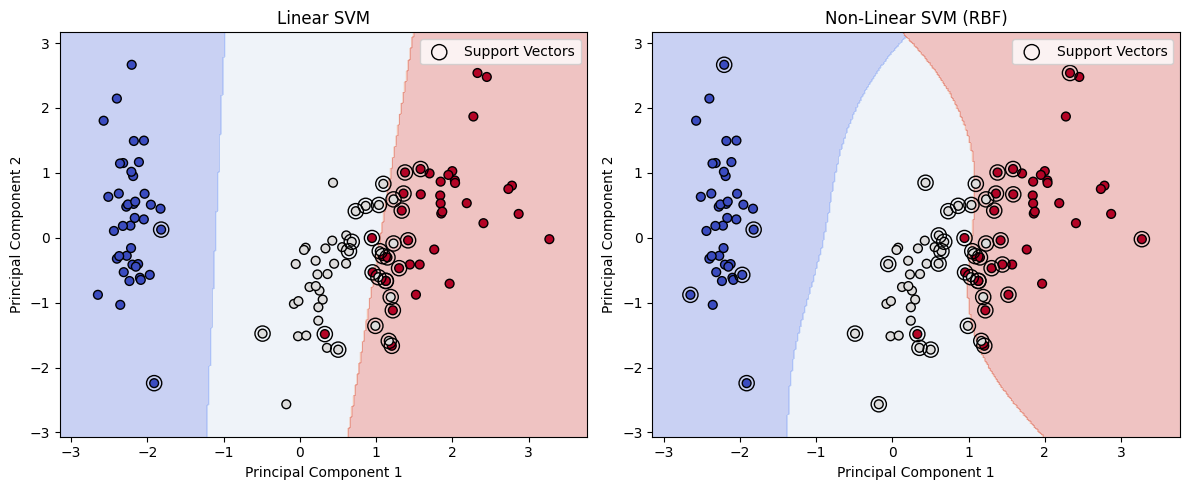

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    (svm_linear, "Linear SVM"),
    (svm_nonlinear, "Non-Linear SVM (RBF)")
]

x_min = X_train_pca[:, 0].min() - 0.5
x_max = X_train_pca[:, 0].max() + 0.5
y_min = X_train_pca[:, 1].min() - 0.5
y_max = X_train_pca[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

for ax, (model, title) in zip(axes, models):
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        alpha=0.3,
        cmap="coolwarm"
    )

    ax.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="black",
        s=40
    )

    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=120,
        facecolors="none",
        edgecolors="black",
        label="Support Vectors"
    )

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend()

plt.tight_layout()
plt.show()

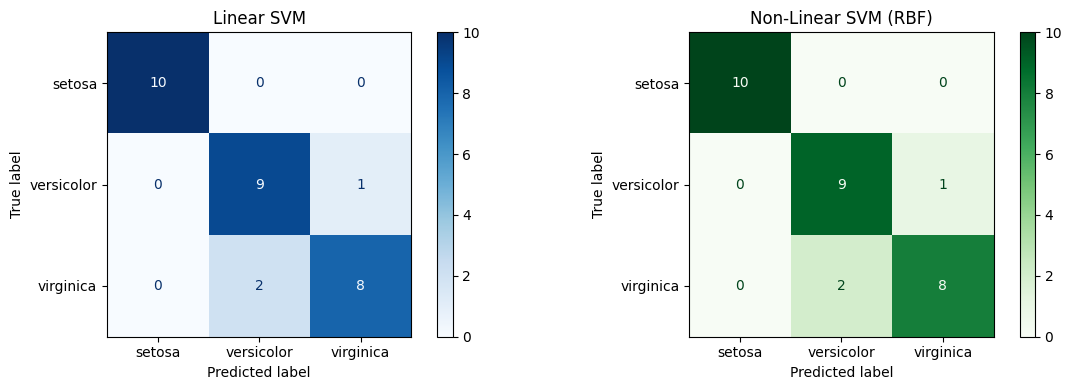

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_estimator(
    svm_linear,
    X_test_pca,
    y_test,
    display_labels=iris.target_names,
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Linear SVM")

ConfusionMatrixDisplay.from_estimator(
    svm_nonlinear,
    X_test_pca,
    y_test,
    display_labels=iris.target_names,
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Non-Linear SVM (RBF)")

plt.tight_layout()
plt.show()

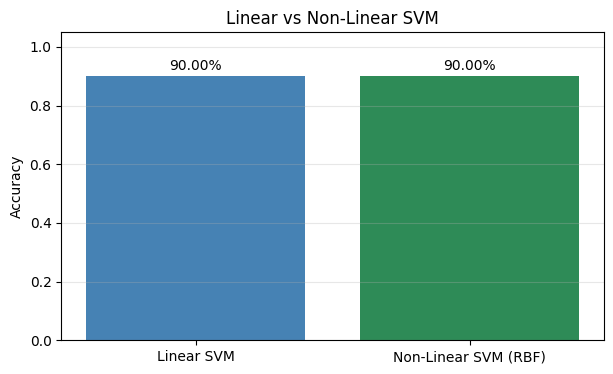

In [21]:
models = ["Linear SVM", "Non-Linear SVM (RBF)"]
accuracies = [accuracy_linear, accuracy_nonlinear]

plt.figure(figsize=(7, 4))

bars = plt.bar(
    models,
    accuracies,
    color=["steelblue", "seagreen"]
)

plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("Linear vs Non-Linear SVM")
plt.grid(axis="y", alpha=0.3)

for bar, acc in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{acc:.2%}",
        ha="center"
    )

plt.show()

In [22]:
results = pd.DataFrame({
    "Model": ["Linear SVM", "Non-Linear SVM (RBF)"],
    "Kernel": ["Linear", "RBF"],
    "Test Accuracy": [accuracy_linear, accuracy_nonlinear]
})

print(results.to_string(index=False))

               Model Kernel  Test Accuracy
          Linear SVM Linear            0.9
Non-Linear SVM (RBF)    RBF            0.9
